# Labor 3: Informationstheorie im Notebook

**Name:**  
**Datum:**  

Bearbeiten Sie die TODO-Stellen. Führen Sie am Ende alle Zellen von oben nach unten aus und speichern Sie das Notebook für Moodle.

Ziel des Labors: Sie vergleichen Textdaten, Zufallsdaten, Entropie und Codewortlängen so, dass die Grenze verlustfreier Kompression praktisch sichtbar wird.


## 1. Setup

Die erste Zelle lädt nur Bibliotheken und Hilfsfunktionen. Hier müssen Sie noch nichts ändern.


In [1]:
import gzip
import math
from collections import Counter

import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)

def gzip_bytes(data: bytes) -> bytes:
    return gzip.compress(data)

def byte_counts(data: bytes):
    values = np.frombuffer(data, dtype=np.uint8)
    return np.bincount(values, minlength=256)

def byte_probabilities(data: bytes):
    counts = byte_counts(data)
    return counts / counts.sum()

def show_size_report(label, original, compressed):
    ratio = len(compressed) / len(original) * 100
    print(f"{label}")
    print(f"  Original:    {len(original):>8} Byte")
    print(f"  Komprimiert: {len(compressed):>8} Byte")
    print(f"  Verhältnis:  {ratio:>8.2f} %")

def plot_byte_histogram(data: bytes, title: str, ax=None):
    if ax is None:
        _, ax = plt.subplots(figsize=(9, 3))
    probs = byte_probabilities(data)
    ax.bar(np.arange(256), probs, width=1.0)
    ax.set_title(title)
    ax.set_xlabel("Bytewert")
    ax.set_ylabel("relative Häufigkeit")
    ax.set_xlim(0, 255)
    return ax


## 2. Textdaten komprimieren

Der Beispieltext ist absichtlich regelmäßig. Ergänzen Sie die Berechnung des Kompressionsverhältnisses.


In [2]:
# load text data from /data/big.txt into a string variable
with open("./data/big.txt", "r", encoding="utf-8") as f:
    basis_text = f.read()

text_data = (basis_text).encode("utf-8")
text_gzip = gzip_bytes(text_data)

# TODO: Ergänzen Sie die Formel für das Verhältnis in Prozent.
kompressionsverhaeltnis_text = len(text_gzip) / len(text_data) * 100

show_size_report("Textdaten", text_data, text_gzip)
print(f"Selbst berechnetes Verhältnis: {kompressionsverhaeltnis_text:.2f} %")


Textdaten
  Original:     6488666 Byte
  Komprimiert:  2373530 Byte
  Verhältnis:     36.58 %
Selbst berechnetes Verhältnis: 36.58 %


**Kurze Deutung:**  
Warum schrumpft der Text? Ergänzen Sie 2 bis 3 Stichpunkte.

- ...
- ...


## 3. Zufallsdaten vergleichen

Nun werden Zufallsdaten mit derselben Länge erzeugt. Ergänzen Sie wieder das Kompressionsverhältnis.


In [3]:
random_data = rng.integers(0, 256, size=len(text_data), dtype=np.uint8).tobytes()
random_gzip = gzip_bytes(random_data)

# TODO: Ergänzen Sie die Formel für das Verhältnis in Prozent.
kompressionsverhaeltnis_zufall = len(random_gzip) / len(random_data) * 100

show_size_report("Zufallsdaten", random_data, random_gzip)
print(f"Selbst berechnetes Verhältnis: {kompressionsverhaeltnis_zufall:.2f} %")


Zufallsdaten
  Original:     6488666 Byte
  Komprimiert:  6490664 Byte
  Verhältnis:    100.03 %
Selbst berechnetes Verhältnis: 100.03 %


**Kurze Deutung:**  
Vergleichen Sie Text und Zufallsdaten. Verwenden Sie die Begriffe `Struktur`, `Vorhersagbarkeit` und `Redundanz`.

> ...


## 4. Verteilungen sichtbar machen

Histogramme zeigen, ob bestimmte Bytewerte deutlich häufiger auftreten als andere.


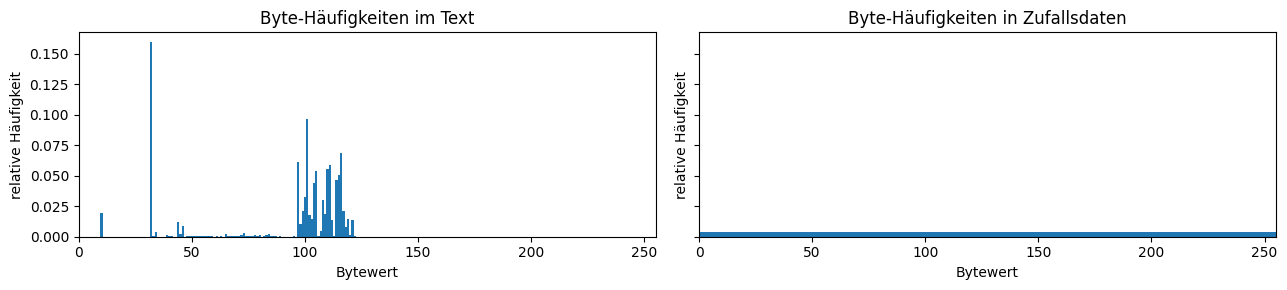

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3), sharey=True)
plot_byte_histogram(text_data, "Byte-Häufigkeiten im Text", axes[0])
plot_byte_histogram(random_data, "Byte-Häufigkeiten in Zufallsdaten", axes[1])
plt.tight_layout()
plt.show()


In [5]:
# TODO: Geben Sie die 10 häufigsten Bytewerte im Text aus.
# Hinweis: Counter(text_data).most_common(10)
haeufigste_textbytes = Counter(text_data).most_common(10)
print("10 häufigste Bytewerte im Text:")
for byte_value, count in haeufigste_textbytes:
    print(f"Bytewert: {byte_value:3d}, Häufigkeit: {count}")
# Als UTF-8 Zeichen
print("\n10 häufigste Bytewerte im Text als UTF-8 Zeichen:")
for byte_value, count in haeufigste_textbytes:
    try:
        char = byte_value.to_bytes(1, 'big').decode('utf-8')
    except UnicodeDecodeError:
        char = '?'
    print(f"Bytewert: {byte_value:3d} ('{char}'), Häufigkeit: {count}")


10 häufigste Bytewerte im Text:
Bytewert:  32, Häufigkeit: 1036511
Bytewert: 101, Häufigkeit: 628234
Bytewert: 116, Häufigkeit: 444459
Bytewert:  97, Häufigkeit: 395872
Bytewert: 111, Häufigkeit: 382683
Bytewert: 110, Häufigkeit: 362397
Bytewert: 105, Häufigkeit: 348464
Bytewert: 115, Häufigkeit: 326238
Bytewert: 114, Häufigkeit: 303977
Bytewert: 104, Häufigkeit: 287323

10 häufigste Bytewerte im Text als UTF-8 Zeichen:
Bytewert:  32 (' '), Häufigkeit: 1036511
Bytewert: 101 ('e'), Häufigkeit: 628234
Bytewert: 116 ('t'), Häufigkeit: 444459
Bytewert:  97 ('a'), Häufigkeit: 395872
Bytewert: 111 ('o'), Häufigkeit: 382683
Bytewert: 110 ('n'), Häufigkeit: 362397
Bytewert: 105 ('i'), Häufigkeit: 348464
Bytewert: 115 ('s'), Häufigkeit: 326238
Bytewert: 114 ('r'), Häufigkeit: 303977
Bytewert: 104 ('h'), Häufigkeit: 287323


**Kurze Deutung:**  
Welche Verteilung wirkt stärker strukturiert? Welche Quelle erwarten Sie mit höherer Entropie?

> ...


## 5. Informationsgehalt

Der Informationsgehalt eines Ereignisses lautet

$$
I(x_i)=-\log_2(P(x_i)).
$$

Ergänzen Sie die Funktion.


In [6]:
def informationsgehalt(p):
    if p <= 0:
        return math.inf
    I = -math.log2(p)
    return I

wahrscheinlichkeiten = [1.0, 0.5, 0.25, 0.1]

# TODO: Ergänzen Sie eine eigene Wahrscheinlichkeit zwischen 0 und 1.
wahrscheinlichkeiten.append(0.05)

for p in wahrscheinlichkeiten:
    print(f"p={p:>5}: I={informationsgehalt(p):.3f} bit")


p=  1.0: I=-0.000 bit
p=  0.5: I=1.000 bit
p= 0.25: I=2.000 bit
p=  0.1: I=3.322 bit
p= 0.05: I=4.322 bit


**Kurze Deutung:**  
Was passiert mit dem Informationsgehalt, wenn die Wahrscheinlichkeit von `0.5` auf `0.25` sinkt?

> ...


## 6. Entropie von Quellen

Entropie ist der mittlere Informationsgehalt einer Quelle:

$$
H(X)=-\sum_i p_i\log_2(p_i).
$$

Ergänzen Sie die Funktion und eine eigene Quelle.


In [8]:
def entropie(probs):
    probs = np.array(probs, dtype=float)
    probs = probs[probs > 0]
    entropie = -np.sum(probs * np.log2(probs))  
    return entropie

quellen = {
    "faire Münze": [0.5, 0.5],
    "gezinkte Münze": [0.9, 0.1],
    "vier gleiche Zeichen": [0.25, 0.25, 0.25, 0.25],
    # TODO: Ersetzen Sie die Werte durch eine eigene gültige Verteilung.
    "eigene Quelle": [0.1, 0.2, 0.3, 0.4]
}

for name, probs in quellen.items():
    print(f"{name:>22}: H={entropie(probs):.3f} bit/Zeichen")


           faire Münze: H=1.000 bit/Zeichen
        gezinkte Münze: H=0.469 bit/Zeichen
  vier gleiche Zeichen: H=2.000 bit/Zeichen
         eigene Quelle: H=1.846 bit/Zeichen


In [9]:
# Wenn die Entropiefunktion funktioniert, können auch die Byte-Verteilungen verglichen werden.
H_text_bytes = entropie(byte_probabilities(text_data))
H_random_bytes = entropie(byte_probabilities(random_data))

print(f"Textdaten:    {H_text_bytes:.3f} bit/Byte")
print(f"Zufallsdaten: {H_random_bytes:.3f} bit/Byte")


Textdaten:    4.511 bit/Byte
Zufallsdaten: 8.000 bit/Byte


**Kurze Deutung:**  
Welche Quelle hat die höchste Entropie? Welche Quelle sollte am besten komprimierbar sein?

> ...


## 7. Huffman-Code auswerten

Für die Quelle aus der Vorlesung wird eine mögliche Huffman-Codetabelle vorgegeben. Prüfen Sie Präfixfreiheit, mittlere Codewortlänge und Abstand zur Entropie.


In [10]:
symbole = ["R", "D", "N", "Z", "L"]
wahrscheinlichkeiten_huffman = np.array([0.38, 0.23, 0.10, 0.09, 0.20])
codes = {
    "R": "10",
    "D": "11",
    "L": "01",
    "N": "001",
    "Z": "000",
}

def ist_praefixfrei(code_dict):
    codewoerter = list(code_dict.values())
    for a in codewoerter:
        for b in codewoerter:
            if a != b and b.startswith(a):
                return False
    return True

def mittlere_codewortlaenge(symbole, probs, code_dict):
    L = np.sum(np.array(probs) * np.array([len(code_dict[s]) for s in symbole]))
    return L

H = entropie(wahrscheinlichkeiten_huffman)
L = mittlere_codewortlaenge(symbole, wahrscheinlichkeiten_huffman, codes)

print("präfixfrei:", ist_praefixfrei(codes))
print(f"H(X) = {H:.3f} bit/Zeichen")
print(f"L    = {L:.3f} bit/Zeichen")
print(f"Abstand L-H = {L-H:.3f} bit/Zeichen")


präfixfrei: True
H(X) = 2.127 bit/Zeichen
L    = 2.190 bit/Zeichen
Abstand L-H = 0.063 bit/Zeichen


**Kurze Deutung:**  
Warum liegt `L` nahe bei `H(X)`, aber nicht darunter?

> ...


## 8. Ergebnisreflexion für Moodle

Fassen Sie die wichtigsten Ergebnisse knapp zusammen.

1. Textdaten schrumpfen stärker als Zufallsdaten, weil ...
2. Entropie beschreibt ...
3. Die höchste Entropie im Notebook hatte ...
4. Die niedrigste Entropie im Notebook hatte ...
5. Der Huffman-Code zeigt, dass ...
6. Eine mögliche Klausurfrage zu diesem Labor wäre ...


## 9. Abgabe

Speichern Sie dieses Notebook nach der Bearbeitung. Geben Sie in Moodle ab:

- die ausgefüllte `.ipynb`-Datei
- optional zusätzlich einen HTML- oder PDF-Export

Vor der Abgabe: `Kernel` neu starten und alle Zellen von oben nach unten ausführen.
